# ShopSphere E-Commerce Data Analysis

## Project Overview
ShopSphere is a fictional e-commerce business operating across cities in India. This project demonstrates an end-to-end analytics workflow using a synthetic 2025 order dataset: data-quality assessment, cleaning, feature engineering, exploratory analysis, business-question analysis, and recommendations.

**Important:** The data is synthetic and is intended for portfolio demonstration, not as evidence of actual company performance.

## Business Questions
1. Which products generate the most revenue and profit?
2. Which customers generate the most revenue and profit?
3. Which cities perform best by revenue and profitability?
4. Which months have the strongest and weakest performance?
5. How do discount levels relate to revenue and profit?
6. How concentrated is profit across products?
7. Which customer segments generate the most value?
8. Which products should receive business attention?
9. Which products have high revenue but below-average profit margins?
10. What actions should management consider?

## Technology Stack
- Python, Pandas, NumPy
- Matplotlib and Seaborn for exploratory visualizations
- Jupyter Notebook
- Streamlit and Plotly for the separate interactive dashboard
- Git and GitHub for version control and portfolio presentation

SQL and Power BI are not claimed as tools used in this notebook.

## 1. Load the Source Dataset
The provided CSV contains 15,000 synthetic order records. The notebook creates a reproducible, intentionally messy copy so that the data-cleaning process can be demonstrated without modifying the source file.

In [1]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

source_path = DATA_DIR / "ecommerce_orders.csv"
df = pd.read_csv(source_path, parse_dates=["OrderDate"])

print(f"Source shape: {df.shape}")
print(f"Unique orders: {df['OrderID'].nunique():,}")
print(f"Unique customers: {df['CustomerID'].nunique():,}")
display(df.head())

Source shape: (15000, 15)
Unique orders: 15,000
Unique customers: 2,000


,OrderID,OrderDate,CustomerID,CustomerName,Product,Category,City,Quantity,UnitPrice,Discount,Revenue,Cost,Profit,PaymentMethod,OrderStatus
0,1,2025-08-29,CUST0879,Customer_879,Monitor,Electronics,Delhi,5,16324.07,0.05,77539.33,53181.56,24357.78,Credit Card,Completed
1,2,2025-11-24,CUST0427,Customer_427,Laptop,Electronics,Mumbai,5,71007.53,0.00,355037.65,246794.26,108243.39,Net Banking,Returned
2,3,2025-12-28,CUST0860,Customer_860,Tablet,Electronics,Chennai,1,20860.69,0.15,17731.59,10769.51,6962.08,Debit Card,Completed
3,4,2025-08-12,CUST0184,Customer_184,Printer,Office,Lucknow,4,11314.96,0.05,42996.85,29111.83,13885.02,UPI,Completed
4,5,2025-06-06,CUST1665,Customer_1665,Keyboard,Accessories,Delhi,2,1637.77,0.20,2620.43,1944.17,676.26,Credit Card,Completed


## 2. Simulate Data-Quality Issues
To make the cleaning workflow realistic, create a copy with missing values, inconsistent city/status labels, invalid quantities, missing unit prices, and duplicate rows. The original source data remains unchanged.

In [2]:
row_df = df.copy()

# Missing values
missing_customer_idx = np.random.choice(row_df.index, size=100, replace=False)
row_df.loc[missing_customer_idx, "CustomerName"] = np.nan

missing_city_idx = np.random.choice(row_df.index, size=50, replace=False)
row_df.loc[missing_city_idx, "City"] = np.nan

missing_price_idx = np.random.choice(row_df.index, size=30, replace=False)
row_df.loc[missing_price_idx, "UnitPrice"] = np.nan

# Inconsistent city labels
city_errors = {
    "Delhi": ["delhi", "DELHI", "Dehli"],
    "Mumbai": ["mumbai", "MUMBAI"],
    "Bangalore": ["bangalore", "BANGALORE", "Bengaluru"],
    "Hyderabad": ["hyderabad", "HYDERABAD"],
    "Chennai": ["chennai", "CHENNAI"],
}
for correct, variants in city_errors.items():
    idx = row_df.index[row_df["City"].eq(correct)]
    idx = idx[:min(20, len(idx))]
    for j, row_index in enumerate(idx):
        row_df.loc[row_index, "City"] = variants[j % len(variants)]

# Inconsistent order-status labels
status_errors = {
    "Completed": ["completed", "COMPLETED"],
    "Cancelled": ["cancelled", "CANCELLED"],
    "Returned": ["returned", "RETURN"],
}
for correct, variants in status_errors.items():
    idx = row_df.index[row_df["OrderStatus"].eq(correct)][:20]
    for j, row_index in enumerate(idx):
        row_df.loc[row_index, "OrderStatus"] = variants[j % len(variants)]

# Invalid quantities
invalid_idx = np.random.choice(row_df.index, size=20, replace=False)
row_df.loc[invalid_idx[:10], "Quantity"] = 0
row_df.loc[invalid_idx[10:], "Quantity"] = -1

# Add 50 duplicate records
duplicates = row_df.sample(n=50, random_state=SEED)
row_df = pd.concat([row_df, duplicates], ignore_index=True)

print(f"Messy dataset shape: {row_df.shape}")

Messy dataset shape: (15050, 15)


## 3. Data Quality Assessment
Before cleaning, inspect missing values, duplicate rows, invalid quantities, category consistency, and financial calculations. These checks help identify which issues need correction before analysis.

In [3]:
quality_summary = pd.DataFrame({
    "MissingValues": row_df.isna().sum(),
    "MissingPercent": (row_df.isna().mean() * 100).round(2),
})
display(quality_summary[quality_summary["MissingValues"] > 0])
print("Exact duplicate rows:", int(row_df.duplicated().sum()))
print("Rows with Quantity <= 0:", int((row_df["Quantity"] <= 0).sum()))
print("Distinct city labels:", sorted(row_df["City"].dropna().astype(str).unique()))
print("Distinct order-status labels:", sorted(row_df["OrderStatus"].dropna().astype(str).unique()))

profit_difference_before = (
    row_df["Profit"] - (row_df["Revenue"] - row_df["Cost"])
).abs()
print("Maximum absolute Profit vs Revenue - Cost difference:",
      round(float(profit_difference_before.max()), 4))

,MissingValues,MissingPercent
CustomerName,150,1.00
City,50,0.33
UnitPrice,30,0.20


Exact duplicate rows: 50
Rows with Quantity <= 0: 20
Distinct city labels: ['BANGALORE', 'Bangalore', 'Bengaluru', 'CHENNAI', 'Chennai', 'DELHI', 'Dehli', 'Dehradun', 'Delhi', 'HYDERABAD', 'Hyderabad', 'Jaipur', 'Kolkata', 'Lucknow', 'MUMBAI', 'Mumbai', 'Pune', 'bangalore', 'chennai', 'delhi', 'hyderabad', 'mumbai']
Distinct order-status labels: ['CANCELLED', 'COMPLETED', 'Cancelled', 'Completed', 'RETURN', 'Returned', 'cancelled', 'completed', 'returned']
Maximum absolute Profit vs Revenue - Cost difference: 0.01


### Assessment Findings
- Missing customer names, cities, and unit prices were introduced.
- Duplicate rows were added intentionally.
- Some city and order-status labels use inconsistent capitalization or spelling.
- Twenty records have invalid quantities (zero or negative).
- Financial calculations are checked with a small tolerance because currency values are rounded to two decimals.

## 4. Data Cleaning
The cleaning steps remove exact duplicates, standardize categorical values, fill recoverable missing values, and exclude records with invalid quantities. The `Profit` field is retained rather than overwritten; small cent-level differences are treated as rounding effects.

In [4]:
cleaned_df = row_df.drop_duplicates().copy()
rows_after_deduplication = len(cleaned_df)

# Standardize city names and handle missing city values
city_mapping = {
    "delhi": "Delhi", "DELHI": "Delhi", "Dehli": "Delhi",
    "mumbai": "Mumbai", "MUMBAI": "Mumbai",
    "bangalore": "Bangalore", "BANGALORE": "Bangalore", "Bengaluru": "Bangalore",
    "hyderabad": "Hyderabad", "HYDERABAD": "Hyderabad",
    "chennai": "Chennai", "CHENNAI": "Chennai",
}
cleaned_df["City"] = cleaned_df["City"].replace(city_mapping).fillna("Unknown")

# Standardize order-status values
status_mapping = {
    "completed": "Completed", "COMPLETED": "Completed",
    "cancelled": "Cancelled", "CANCELLED": "Cancelled",
    "returned": "Returned", "RETURN": "Returned",
}
cleaned_df["OrderStatus"] = cleaned_df["OrderStatus"].replace(status_mapping)

# Recover missing names from the customer ID/name pairs in the source dataset
customer_lookup = df.drop_duplicates("CustomerID").set_index("CustomerID")["CustomerName"]
cleaned_df["CustomerName"] = cleaned_df["CustomerName"].fillna(
    cleaned_df["CustomerID"].map(customer_lookup)
)

# Recover unit price from Revenue = Quantity * UnitPrice * (1 - Discount)
price_mask = cleaned_df["UnitPrice"].isna()
valid_price_mask = price_mask & cleaned_df["Quantity"].gt(0) & cleaned_df["Discount"].lt(1)
cleaned_df.loc[valid_price_mask, "UnitPrice"] = (
    cleaned_df.loc[valid_price_mask, "Revenue"]
    / (cleaned_df.loc[valid_price_mask, "Quantity"] *
       (1 - cleaned_df.loc[valid_price_mask, "Discount"]))
).round(2)

# Remove records with zero or negative quantities
invalid_quantity_count = int((cleaned_df["Quantity"] <= 0).sum())
cleaned_df = cleaned_df.loc[cleaned_df["Quantity"] > 0].copy()

print("Rows after duplicate removal:", rows_after_deduplication)
print("Invalid-quantity rows removed:", invalid_quantity_count)
print("Cleaned dataset shape:", cleaned_df.shape)

Rows after duplicate removal: 15000
Invalid-quantity rows removed: 20
Cleaned dataset shape: (14980, 15)


In [5]:
# Validate the cleaned dataset
validation = {
    "Rows": len(cleaned_df),
    "Columns": cleaned_df.shape[1],
    "Duplicate rows": int(cleaned_df.duplicated().sum()),
    "Missing cells": int(cleaned_df.isna().sum().sum()),
    "Invalid quantity rows": int((cleaned_df["Quantity"] <= 0).sum()),
    "Unique orders": int(cleaned_df["OrderID"].nunique()),
    "Unique customers": int(cleaned_df["CustomerID"].nunique()),
}
display(pd.Series(validation, name="Validation result"))
display(cleaned_df.isna().sum().rename("Missing values").to_frame().query("`Missing values` > 0"))

Rows                     14980
Columns                     15
Duplicate rows               0
Missing cells                0
Invalid quantity rows        0
Unique orders            14980
Unique customers          2000
Name: Validation result, dtype: int64

,Missing values


## 5. Feature Engineering
Create date features and profit margin for monthly, weekday, and profitability analysis.

In [6]:
cleaned_df["OrderDate"] = pd.to_datetime(cleaned_df["OrderDate"], errors="coerce")
cleaned_df["Year"] = cleaned_df["OrderDate"].dt.year
cleaned_df["Month"] = cleaned_df["OrderDate"].dt.month
cleaned_df["MonthName"] = cleaned_df["OrderDate"].dt.month_name()
cleaned_df["DayOfWeek"] = cleaned_df["OrderDate"].dt.day_name()
cleaned_df["ProfitMargin"] = np.where(
    cleaned_df["Revenue"].ne(0),
    cleaned_df["Profit"] / cleaned_df["Revenue"] * 100,
    np.nan
)
cleaned_df["ProfitMargin"] = cleaned_df["ProfitMargin"].round(2)

cleaned_df.to_csv(DATA_DIR / "cleaned_ecommerce_orders.csv", index=False)
print("Exported cleaned dataset to data/cleaned_ecommerce_orders.csv")
display(cleaned_df.head())

Exported cleaned dataset to data/cleaned_ecommerce_orders.csv


,OrderID,OrderDate,CustomerID,CustomerName,Product,Category,City,Quantity,UnitPrice,Discount,Revenue,Cost,Profit,PaymentMethod,OrderStatus,Year,Month,MonthName,DayOfWeek,ProfitMargin
0,1,2025-08-29,CUST0879,Customer_879,Monitor,Electronics,Delhi,5,16324.07,0.05,77539.33,53181.56,24357.78,Credit Card,Completed,2025,8,August,Friday,31.41
1,2,2025-11-24,CUST0427,Customer_427,Laptop,Electronics,Mumbai,5,71007.53,0.00,355037.65,246794.26,108243.39,Net Banking,Returned,2025,11,November,Monday,30.49
2,3,2025-12-28,CUST0860,Customer_860,Tablet,Electronics,Unknown,1,20860.69,0.15,17731.59,10769.51,6962.08,Debit Card,Completed,2025,12,December,Sunday,39.26
3,4,2025-08-12,CUST0184,Customer_184,Printer,Office,Lucknow,4,11314.96,0.05,42996.85,29111.83,13885.02,UPI,Completed,2025,8,August,Tuesday,32.29
4,5,2025-06-06,CUST1665,Customer_1665,Keyboard,Accessories,Delhi,2,1637.77,0.20,2620.43,1944.17,676.26,Credit Card,Completed,2025,6,June,Friday,25.81


## 6. Exploratory Data Analysis and Key Performance Indicators
The headline metrics below summarize the cleaned dataset. Because the source assigns revenue and profit to every order status, these totals include Completed, Cancelled, and Returned orders; they should not be interpreted as realized net sales without additional financial-status rules.

In [7]:
total_revenue = cleaned_df["Revenue"].sum()
total_cost = cleaned_df["Cost"].sum()
total_profit = cleaned_df["Profit"].sum()
total_orders = cleaned_df["OrderID"].nunique()
total_customers = cleaned_df["CustomerID"].nunique()
total_quantity = cleaned_df["Quantity"].sum()
average_order_value = total_revenue / total_orders if total_orders else np.nan
overall_profit_margin = total_profit / total_revenue * 100 if total_revenue else np.nan

kpis = pd.DataFrame({
    "Metric": ["Total Revenue", "Total Cost", "Total Profit", "Total Orders",
               "Total Customers", "Total Quantity", "Average Order Value",
               "Overall Profit Margin (%)"],
    "Value": [total_revenue, total_cost, total_profit, total_orders,
              total_customers, total_quantity, average_order_value,
              overall_profit_margin]
})
display(kpis.style.format({"Value": lambda x: f"{x:,.2f}" if isinstance(x, (int, float, np.number)) else x}))

,Metric,Value
0,Total Revenue,"647,974,229.00"
1,Total Cost,"469,825,731.93"
2,Total Profit,"178,148,497.65"
3,Total Orders,"14,980.00"
4,Total Customers,"2,000.00"
5,Total Quantity,"45,168.00"
6,Average Order Value,"43,255.96"
7,Overall Profit Margin (%),27.49


In [8]:
monthly_sales = (
    cleaned_df.groupby(["Month", "MonthName"], as_index=False)
    .agg(Revenue=("Revenue", "sum"), Cost=("Cost", "sum"),
         Profit=("Profit", "sum"), Orders=("OrderID", "nunique"),
         Quantity=("Quantity", "sum"))
    .sort_values("Month")
)
monthly_sales["ProfitMargin"] = (monthly_sales["Profit"] / monthly_sales["Revenue"] * 100).round(2)
display(monthly_sales)
print("Highest revenue month:", monthly_sales.loc[monthly_sales["Revenue"].idxmax(), "MonthName"])
print("Lowest revenue month:", monthly_sales.loc[monthly_sales["Revenue"].idxmin(), "MonthName"])

,Month,MonthName,Revenue,Cost,Profit,Orders,Quantity,ProfitMargin
0,1,January,51174751.86,37470895.18,13703856.76,1244,3731,26.78
1,2,February,50751434.67,36899271.69,13852163.03,1180,3508,27.29
2,3,March,60438977.57,44151230.01,16287747.37,1299,4021,26.95
3,4,April,52789201.26,38156340.33,14632861.03,1174,3577,27.72
4,5,May,49383201.22,35601971.50,13781229.78,1228,3694,27.91
5,6,June,55975103.42,40448072.18,15527031.28,1236,3740,27.74
6,7,July,53149293.52,38315818.45,14833475.31,1235,3684,27.91
7,8,August,58790597.12,42396775.79,16393821.29,1326,3981,27.89
8,9,September,52933617.00,38447561.77,14486055.43,1239,3723,27.37
9,10,October,48691932.93,35068347.60,13623585.47,1251,3736,27.98


Highest revenue month: March
Lowest revenue month: October


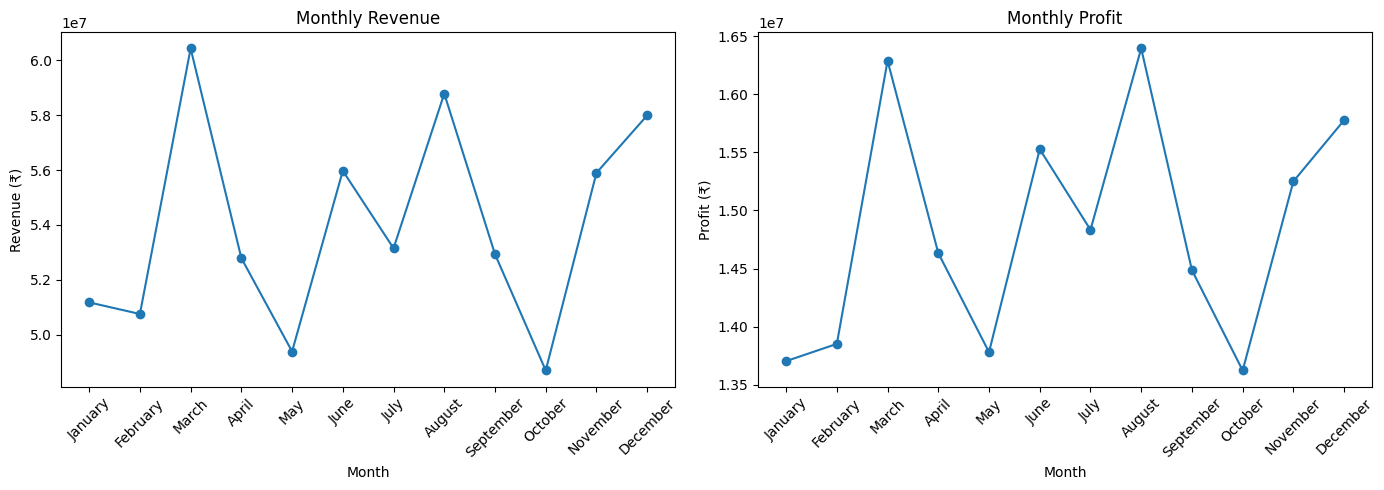

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(monthly_sales["MonthName"], monthly_sales["Revenue"], marker="o")
axes[0].set_title("Monthly Revenue")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue (₹)")
axes[0].tick_params(axis="x", rotation=45)
axes[1].plot(monthly_sales["MonthName"], monthly_sales["Profit"], marker="o")
axes[1].set_title("Monthly Profit")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Profit (₹)")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 7. Business Question Analysis
### 7.1 Which products generate the most revenue and profit?

In [10]:
product_sales = (
    cleaned_df.groupby(["Product", "Category"], as_index=False)
    .agg(Revenue=("Revenue", "sum"), Cost=("Cost", "sum"),
         Profit=("Profit", "sum"), Orders=("OrderID", "nunique"),
         Quantity=("Quantity", "sum"))
)
product_sales["ProfitMargin"] = (product_sales["Profit"] / product_sales["Revenue"] * 100).round(2)
product_sales = product_sales.sort_values("Revenue", ascending=False)
display(product_sales)

,Product,Category,Revenue,Cost,Profit,Orders,Quantity,ProfitMargin
2,Laptop,Electronics,2.690048e+08,1.949908e+08,74013988.94,1505,4590,27.51
6,Smartphone,Electronics,1.182022e+08,8.543431e+07,32767897.33,1475,4396,27.72
8,Tablet,Electronics,9.100920e+07,6.604478e+07,24964422.63,1522,4599,27.43
3,Monitor,Electronics,5.926889e+07,4.312967e+07,16139219.63,1447,4390,27.23
5,Printer,Office,4.718755e+07,3.424717e+07,12940380.14,1445,4366,27.42
7,Smartwatch,Wearables,2.945356e+07,2.144044e+07,8013121.62,1549,4684,27.21
9,Webcam,Accessories,1.411338e+07,1.025325e+07,3860128.79,1483,4497,27.35
0,Headphones,Accessories,1.030774e+07,7.444335e+06,2863404.24,1503,4577,27.78
1,Keyboard,Accessories,6.152383e+06,4.462005e+06,1690377.27,1508,4531,27.48
4,Mouse,Accessories,3.274544e+06,2.378987e+06,895557.06,1543,4538,27.35


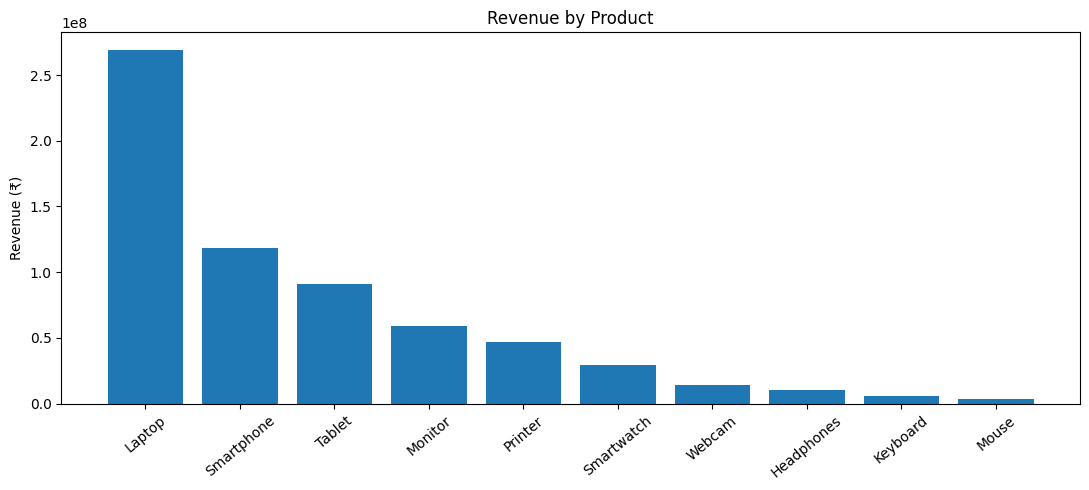

In [11]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(product_sales["Product"], product_sales["Revenue"])
ax.set_title("Revenue by Product")
ax.set_ylabel("Revenue (₹)")
ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.show()

### 7.2 Which customers generate the most revenue and profit?

In [12]:
customer_sales = (
    cleaned_df.groupby(["CustomerID", "CustomerName"], as_index=False)
    .agg(Revenue=("Revenue", "sum"), Profit=("Profit", "sum"),
         Orders=("OrderID", "nunique"), Quantity=("Quantity", "sum"))
    .sort_values("Revenue", ascending=False)
)
display(customer_sales.head(10))

,CustomerID,CustomerName,Revenue,Profit,Orders,Quantity
1135,CUST1135,Customer_1135,1589450.88,471960.30,13,43
1493,CUST1494,Customer_1494,1337625.99,270034.99,13,41
41,CUST0041,Customer_41,1169681.14,274525.14,14,46
1710,CUST1711,Customer_1711,1075904.76,274263.02,12,41
1946,CUST1947,Customer_1947,1075795.99,308880.85,13,45
1446,CUST1446,Customer_1446,1068183.54,256296.89,11,39
1286,CUST1286,Customer_1286,1064270.37,360266.26,10,33
899,CUST0899,Customer_899,1054566.43,258037.44,14,54
346,CUST0346,Customer_346,1050384.02,304432.52,8,29
735,CUST0735,Customer_735,1047897.04,342110.36,16,53


### 7.3 Which cities perform best?

In [13]:
city_sales = (
    cleaned_df.groupby("City", as_index=False)
    .agg(Revenue=("Revenue", "sum"), Cost=("Cost", "sum"),
         Profit=("Profit", "sum"), Orders=("OrderID", "nunique"))
)
city_sales["ProfitMargin"] = (city_sales["Profit"] / city_sales["Revenue"] * 100).round(2)
city_sales = city_sales.sort_values("Revenue", ascending=False)
display(city_sales)

,City,Revenue,Cost,Profit,Orders,ProfitMargin
4,Hyderabad,69679468.56,50623285.48,19056183.18,1509,27.35
3,Delhi,68730569.96,49633050.12,19097519.90,1505,27.79
1,Chennai,64352241.39,46762771.48,17589470.11,1500,27.33
9,Pune,64321946.34,46582484.82,17739461.43,1449,27.58
0,Bangalore,63597946.59,46367075.98,17230870.85,1493,27.09
2,Dehradun,63482987.66,46096149.67,17386838.01,1522,27.39
7,Lucknow,63273182.88,45411116.69,17862066.25,1488,28.23
5,Jaipur,63261518.83,45852151.00,17409367.77,1474,27.52
6,Kolkata,62772910.39,45414186.78,17358723.55,1511,27.65
8,Mumbai,61963123.61,45264470.96,16698652.72,1479,26.95


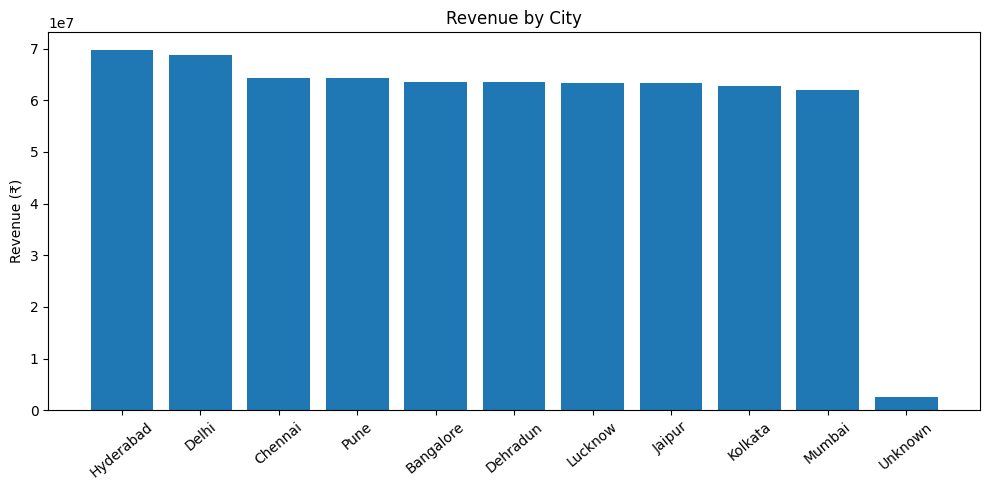

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(city_sales["City"], city_sales["Revenue"])
ax.set_title("Revenue by City")
ax.set_ylabel("Revenue (₹)")
ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.show()

### 7.4 How do discount levels relate to revenue and profit?

In [15]:
discount_analysis = (
    cleaned_df.groupby("Discount", as_index=False)
    .agg(Orders=("OrderID", "nunique"), Revenue=("Revenue", "sum"),
         Profit=("Profit", "sum"), Quantity=("Quantity", "sum"))
)
discount_analysis["ProfitMargin"] = (discount_analysis["Profit"] / discount_analysis["Revenue"] * 100).round(2)
display(discount_analysis.sort_values("Discount"))

,Discount,Orders,Revenue,Profit,Quantity,ProfitMargin
0,0.00,3002,1.406945e+08,38735429.62,9052,27.53
1,0.05,2929,1.321532e+08,36029813.43,8782,27.26
2,0.10,2988,1.321169e+08,36376034.16,9073,27.53
3,0.15,3038,1.240709e+08,34269797.19,9200,27.62
4,0.20,3023,1.189388e+08,32737423.25,9061,27.52


Discount groups can differ in order volume, product mix, and customer mix. This descriptive comparison does **not** establish that discounts cause revenue or profit to rise or fall.

### 7.5 How concentrated is profit across products?

In [16]:
product_profit_share = product_sales[["Product", "Revenue", "Profit"]].copy()
product_profit_share["ProfitSharePct"] = product_profit_share["Profit"] / product_profit_share["Profit"].sum() * 100
product_profit_share = product_profit_share.sort_values("Profit", ascending=False)
product_profit_share["CumulativeProfitSharePct"] = product_profit_share["ProfitSharePct"].cumsum()
product_profit_share[["ProfitSharePct", "CumulativeProfitSharePct"]] = product_profit_share[["ProfitSharePct", "CumulativeProfitSharePct"]].round(2)
display(product_profit_share)

,Product,Revenue,Profit,ProfitSharePct,CumulativeProfitSharePct
2,Laptop,2.690048e+08,74013988.94,41.55,41.55
6,Smartphone,1.182022e+08,32767897.33,18.39,59.94
8,Tablet,9.100920e+07,24964422.63,14.01,73.95
3,Monitor,5.926889e+07,16139219.63,9.06,83.01
5,Printer,4.718755e+07,12940380.14,7.26,90.28
7,Smartwatch,2.945356e+07,8013121.62,4.50,94.77
9,Webcam,1.411338e+07,3860128.79,2.17,96.94
0,Headphones,1.030774e+07,2863404.24,1.61,98.55
1,Keyboard,6.152383e+06,1690377.27,0.95,99.50
4,Mouse,3.274544e+06,895557.06,0.50,100.00


### 7.6 Which customer segments generate the most value?

In [17]:
customer_frequency = (
    cleaned_df.groupby(["CustomerID", "CustomerName"], as_index=False)
    .agg(Orders=("OrderID", "nunique"), Revenue=("Revenue", "sum"),
         Profit=("Profit", "sum"), Quantity=("Quantity", "sum"))
)
customer_frequency["CustomerSegment"] = np.select(
    [customer_frequency["Orders"].eq(1),
     customer_frequency["Orders"].between(2, 4),
     customer_frequency["Orders"].ge(5)],
    ["One-time", "Occasional", "Frequent"],
    default="Unclassified"
)
segment_analysis = (
    customer_frequency.groupby("CustomerSegment", as_index=False)
    .agg(Customers=("CustomerID", "nunique"), Revenue=("Revenue", "sum"),
         Profit=("Profit", "sum"), Orders=("Orders", "sum"))
)
segment_analysis["RevenueSharePct"] = (segment_analysis["Revenue"] / segment_analysis["Revenue"].sum() * 100).round(2)
segment_analysis["RevenuePerCustomer"] = (segment_analysis["Revenue"] / segment_analysis["Customers"]).round(2)
segment_analysis["ProfitPerCustomer"] = (segment_analysis["Profit"] / segment_analysis["Customers"]).round(2)
display(segment_analysis)

,CustomerSegment,Customers,Revenue,Profit,Orders,RevenueSharePct,RevenuePerCustomer,ProfitPerCustomer
0,Frequent,1741,6.098177e+08,1.678141e+08,14093,94.11,350268.65,96389.48
1,Occasional,252,3.752771e+07,1.017001e+07,880,5.79,148919.49,40357.19
2,One-time,7,6.288009e+05,1.644007e+05,7,0.10,89828.70,23485.82


### 7.7 Which products should receive business attention?

In [18]:
product_priority = product_sales[["Product", "Revenue", "Profit", "ProfitMargin"]].copy()
product_priority["RevenueRank"] = product_priority["Revenue"].rank(ascending=False, method="min").astype(int)
product_priority["ProfitRank"] = product_priority["Profit"].rank(ascending=False, method="min").astype(int)
product_priority["MarginRank"] = product_priority["ProfitMargin"].rank(ascending=False, method="min").astype(int)
product_priority["PriorityScore"] = product_priority[["RevenueRank", "ProfitRank", "MarginRank"]].sum(axis=1)
product_priority = product_priority.sort_values(["PriorityScore", "Revenue"], ascending=[True, False])
display(product_priority)

,Product,Revenue,Profit,ProfitMargin,RevenueRank,ProfitRank,MarginRank,PriorityScore
2,Laptop,2.690048e+08,74013988.94,27.51,1,1,3,5
6,Smartphone,1.182022e+08,32767897.33,27.72,2,2,2,6
8,Tablet,9.100920e+07,24964422.63,27.43,3,3,5,11
5,Printer,4.718755e+07,12940380.14,27.42,5,5,6,16
3,Monitor,5.926889e+07,16139219.63,27.23,4,4,9,17
0,Headphones,1.030774e+07,2863404.24,27.78,8,8,1,17
9,Webcam,1.411338e+07,3860128.79,27.35,7,7,7,21
7,Smartwatch,2.945356e+07,8013121.62,27.21,6,6,10,22
1,Keyboard,6.152383e+06,1690377.27,27.48,9,9,4,22
4,Mouse,3.274544e+06,895557.06,27.35,10,10,7,27


The priority score gives equal weight to revenue rank, profit rank, and margin rank. It is a simple screening tool, not a statistically optimized or universally valid prioritization model. Closely grouped margins should not be over-interpreted.

### 7.8 Which products have high revenue but below-average margins?

In [19]:
average_product_revenue = product_sales["Revenue"].mean()
average_product_margin = product_sales["ProfitMargin"].mean()
high_revenue_low_margin = product_sales[
    (product_sales["Revenue"] > average_product_revenue) &
    (product_sales["ProfitMargin"] < average_product_margin)
].sort_values("Revenue", ascending=False)
print(f"Average product revenue: ₹{average_product_revenue:,.2f}")
print(f"Average product margin: {average_product_margin:.2f}%")
display(high_revenue_low_margin)

Average product revenue: ₹64,797,422.90
Average product margin: 27.45%


,Product,Category,Revenue,Cost,Profit,Orders,Quantity,ProfitMargin
8,Tablet,Electronics,91009200.54,66044778.37,24964422.63,1522,4599,27.43


### 7.9 What do order status and payment methods show?

In [20]:
status_analysis = (
    cleaned_df.groupby("OrderStatus", as_index=False)
    .agg(Orders=("OrderID", "nunique"), Revenue=("Revenue", "sum"), Profit=("Profit", "sum"))
)
status_analysis["OrderSharePct"] = (status_analysis["Orders"] / status_analysis["Orders"].sum() * 100).round(2)
payment_analysis = (
    cleaned_df.groupby("PaymentMethod", as_index=False)
    .agg(Orders=("OrderID", "nunique"), Revenue=("Revenue", "sum"), Profit=("Profit", "sum"))
)
payment_analysis["OrderSharePct"] = (payment_analysis["Orders"] / payment_analysis["Orders"].sum() * 100).round(2)
display(status_analysis)
display(payment_analysis)

,OrderStatus,Orders,Revenue,Profit,OrderSharePct
0,Cancelled,2459,1.056019e+08,2.912996e+07,16.42
1,Completed,10078,4.381051e+08,1.206962e+08,67.28
2,Returned,2443,1.042672e+08,2.832232e+07,16.31


,PaymentMethod,Orders,Revenue,Profit,OrderSharePct
0,Cash on Delivery,3001,1.292520e+08,35980982.04,20.03
1,Credit Card,3005,1.313980e+08,36281645.66,20.06
2,Debit Card,2990,1.303530e+08,35934133.08,19.96
3,Net Banking,3006,1.331082e+08,36069540.72,20.07
4,UPI,2978,1.238631e+08,33882196.15,19.88


**Interpretation caveat:** Revenue and profit are populated for every order status in this synthetic source. Therefore, status-level financial totals should be treated as generated transaction values, not confirmed realized sales or refunds. A real business analysis would reconcile statuses with payment, refund, and fulfillment data.

### 7.10 What operational patterns appear by day of week?

In [21]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_analysis = (
    cleaned_df.groupby("DayOfWeek", as_index=False)
    .agg(Revenue=("Revenue", "sum"), Profit=("Profit", "sum"),
         Orders=("OrderID", "nunique"), Quantity=("Quantity", "sum"))
)
day_analysis["DayOfWeek"] = pd.Categorical(day_analysis["DayOfWeek"], categories=weekday_order, ordered=True)
day_analysis = day_analysis.sort_values("DayOfWeek")
display(day_analysis)

,DayOfWeek,Revenue,Profit,Orders,Quantity
1,Monday,93551674.52,25451375.83,2122,6330
5,Tuesday,93389025.03,25538552.44,2108,6343
6,Wednesday,98176192.94,26941952.32,2216,6599
4,Thursday,87972199.66,24516409.02,2140,6501
0,Friday,92425161.94,25291215.96,2124,6603
2,Saturday,90679050.46,25371429.34,2080,6249
3,Sunday,91780924.45,25037562.74,2190,6543


## 8. Key Findings and Business Recommendations
Use the result tables above to support these evidence-led recommendations. The exact ranking and values come from the cleaned dataset generated when this notebook runs.
- **Product strategy:** Protect availability and customer experience for products contributing the largest revenue and profit. Review product-level margins before changing prices or promotions.
- **Customer retention:** Use the customer-segment table to identify repeat customers and test retention offers; measure incremental profit, not just order count.
- **Pricing and discounts:** Compare discount levels with order mix and margin. Use controlled tests before claiming discounts cause changes in performance.
- **Geographic planning:** Compare city revenue, order volume, and margin together rather than ranking cities on revenue alone.
- **Operations:** Investigate cancellation and return rates with actual order lifecycle, payment, and refund data.
- **Data governance:** Add validation rules for quantity, price, status labels, duplicate identifiers, and financial reconciliation.

## 9. Limitations
- The dataset is synthetic and does not represent a real company.
- The data-generation process assigns financial values to all order statuses; actual net sales may differ.
- Observational group comparisons and correlations do not prove causation.
- The customer segmentation thresholds (1 order, 2–4 orders, 5+ orders) are practical definitions chosen for this project, not industry standards.
- Recovered missing unit prices are estimated from the revenue formula and rounded to two decimal places.

## 10. Export Analysis Tables
The key summary tables are exported so they can be reused by the separate dashboard or reviewed without rerunning every analysis.

In [22]:
product_sales.to_csv(OUTPUT_DIR / "product_sales.csv", index=False)
monthly_sales.to_csv(OUTPUT_DIR / "monthly_sales.csv", index=False)
city_sales.to_csv(OUTPUT_DIR / "city_sales.csv", index=False)
segment_analysis.to_csv(OUTPUT_DIR / "customer_segments.csv", index=False)
status_analysis.to_csv(OUTPUT_DIR / "order_status.csv", index=False)
payment_analysis.to_csv(OUTPUT_DIR / "payment_methods.csv", index=False)
print("Exported summary tables to outputs/")
print("Final cleaned dataset:", cleaned_df.shape)

Exported summary tables to outputs/
Final cleaned dataset: (14980, 20)


## Conclusion
This project demonstrates a complete, reproducible analytics workflow: identify data-quality problems, clean and validate data, engineer useful features, answer business questions, and translate findings into recommendations. The accompanying Streamlit dashboard provides an interactive way to explore the cleaned dataset.